In [1]:
import pandas as pd, numpy as np, lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score

train = pd.read_parquet("../data/processed/train.parquet")
val = pd.read_parquet("../data/processed/val.parquet")
features = [c for c in train.columns if c not in ("Time", "Class")]
X_train, y_train = train[features], train["Class"]
X_val, y_val = val[features], val["Class"]
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print(neg, pos, round(neg / pos, 1))

198980 384 518.2


In [3]:
results = {}
for name, spw in [("spw=1", 1.0), ("spw=sqrt", (neg / pos) ** 0.5), ("spw=full", neg / pos)]:
    m = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.03, num_leaves=15,
        min_child_samples=20, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=spw,
        metric="average_precision", random_state=42, n_jobs=-1, verbose=-1,
    )
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    p = m.predict_proba(X_val)[:, 1]
    results[name] = (m, p)
    print(f"{name:9s} best_iter={m.best_iteration_:4d}  "
          f"PR-AUC={average_precision_score(y_val, p):.4f}  ROC-AUC={roc_auc_score(y_val, p):.4f}")

c:\dev\fraud-detection-mlops\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


spw=1     best_iter= 145  PR-AUC=0.8514  ROC-AUC=0.9868


c:\dev\fraud-detection-mlops\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


spw=sqrt  best_iter= 103  PR-AUC=0.8765  ROC-AUC=0.9877


c:\dev\fraud-detection-mlops\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


spw=full  best_iter=1255  PR-AUC=0.8423  ROC-AUC=0.9599


In [4]:
best_name = max(results, key=lambda k: average_precision_score(y_val, results[k][1]))
model, p_val = results[best_name]
print("Selected:", best_name)

Selected: spw=sqrt


No model (all fraud missed): 8,398
Flag at 0.5               : 281
Best threshold 0.63       : 247
At best threshold: flagged=66, precision=0.727, recall=0.857


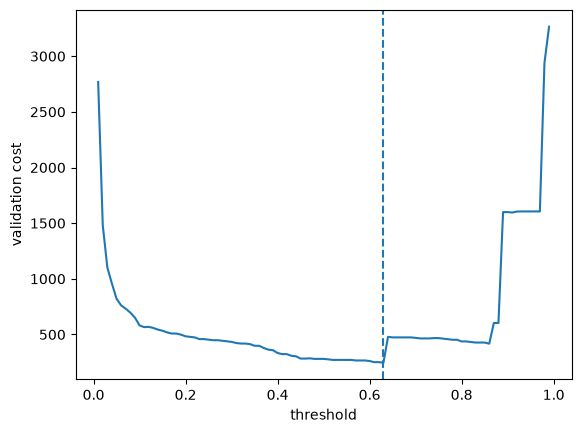

review cost   1: best threshold=0.63, cost=175
review cost   5: best threshold=0.63, cost=247
review cost  20: best threshold=0.86, cost=463
review cost  50: best threshold=0.86, cost=553


In [5]:
amount = val["Amount"].values
y = y_val.values

def total_cost(thr, review_cost):
    flagged = p_val >= thr
    missed_fraud_loss = amount[(y == 1) & ~flagged].sum()
    review_loss = review_cost * ((y == 0) & flagged).sum()
    return missed_fraud_loss + review_loss

thresholds = np.linspace(0.01, 0.99, 99)
REVIEW_COST = 5.0
costs = [total_cost(t, REVIEW_COST) for t in thresholds]
best_thr = thresholds[int(np.argmin(costs))]

print(f"No model (all fraud missed): {amount[y == 1].sum():,.0f}")
print(f"Flag at 0.5               : {total_cost(0.5, REVIEW_COST):,.0f}")
print(f"Best threshold {best_thr:.2f}       : {min(costs):,.0f}")

flagged = p_val >= best_thr
print(f"At best threshold: flagged={flagged.sum()}, "
      f"precision={precision_score(y, flagged):.3f}, recall={recall_score(y, flagged):.3f}")

plt.plot(thresholds, costs); plt.axvline(best_thr, ls="--")
plt.xlabel("threshold"); plt.ylabel("validation cost"); plt.show()

for rc in [1, 5, 20, 50]:
    c = [total_cost(t, rc) for t in thresholds]
    print(f"review cost {rc:>3}: best threshold={thresholds[int(np.argmin(c))]:.2f}, cost={min(c):,.0f}")

thr=0.500  raw cost=   281  flagged= 74  precision=0.662  recall=0.875
thr=0.630  raw cost=   247  flagged= 66  precision=0.727  recall=0.857
thr=0.580  raw cost=   267  flagged= 70  precision=0.686  recall=0.857
Chosen threshold: 0.58


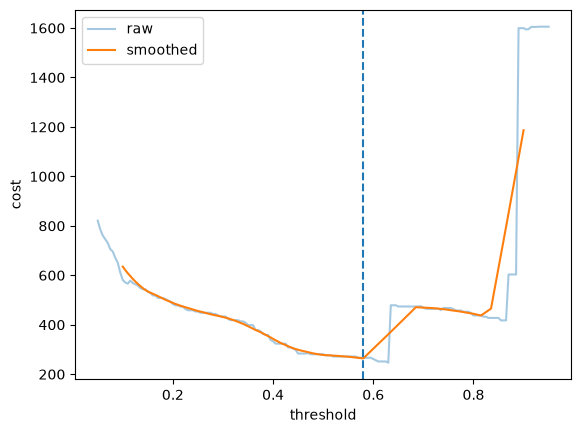

In [6]:
thr_grid = np.linspace(0.05, 0.95, 181)          # step 0.005
c = np.array([total_cost(t, REVIEW_COST) for t in thr_grid])
w = 21                                            # about +/-0.05 window
smooth = np.convolve(c, np.ones(w) / w, mode="same")
core = slice(w // 2, -(w // 2))
t_star = thr_grid[core][smooth[core].argmin()]

for t in [0.50, 0.63, t_star]:
    fl = p_val >= t
    print(f"thr={t:.3f}  raw cost={total_cost(t, REVIEW_COST):6.0f}  flagged={fl.sum():3d}  "
          f"precision={precision_score(y, fl):.3f}  recall={recall_score(y, fl):.3f}")
print("Chosen threshold:", round(float(t_star), 3))

plt.plot(thr_grid, c, alpha=0.4, label="raw")
plt.plot(thr_grid[core], smooth[core], label="smoothed")
plt.axvline(t_star, ls="--"); plt.legend(); plt.xlabel("threshold"); plt.ylabel("cost"); plt.show()